# UDepth — FLSea

Inferência do UDepth-RMI com pesos oficiais congelados, sem treinamento no FLSea. Usa o avaliador da main fixada em `1ad6133260c07cbcef754777b3f7390ade8e1a43`, com a correção da PR #2 que torna o salvamento opcional. As fórmulas das métricas e os alinhamentos da main são preservados.

O conjunto comum contém 120 pares RGB/referência do FLSea-VI v5. A avaliação espera 119 frames válidos e **357 linhas**: `ssi`, `median` e `control`, com **SILog λ = 1**. A linha `raw` não representa profundidade métrica do UDepth.

Os resultados só estão concluídos quando a seção 3 imprime `VALIDACAO_TECNICA_CONCLUIDA`. O salvamento serve à visualização e é opcional; para produzir os PNGs e NPYs da entrega, mantenha `SALVAR_PREDICOES = True`.

Os CSVs antigos dos colegas ainda não foram recalculados para este protocolo. A checagem de comparabilidade verifica os mesmos IDs, frações válidas e controle nas métricas não alteradas; o SILog antigo não é usado na comparação.

## 1. Configuração

CPU é suficiente e GPU é opcional. Conecte o Drive de vma3@cin.ufpe.br. Os novos resultados ficam em outra pasta. O cache da execução anterior só é reaproveitado quando protocolo, imagem e hashes conferem; as métricas são calculadas novamente com o avaliador atual.

In [2]:
from pathlib import Path
import importlib.util, json, os, sys, subprocess
MONTAR_DRIVE = True
DISPOSITIVO = 'auto'
PASTA_FLSEA_LOCAL = ''
SALVAR_PREDICOES = True
EXIBIR_FIGURAS = True
try:
    EM_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    EM_COLAB = False
if EM_COLAB and MONTAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/projeto_profundidade')
else:
    BASE = Path.cwd()/'resultados'
ROOT = BASE/'UDepth_FLSea_1ad6133_silog1_120'
ROOT.mkdir(parents=True,exist_ok=True)
REPO_DIR = (Path('/content') if EM_COLAB else Path.cwd())/'Yolo_Depth_udepth_1ad6133'
ASSETS = BASE/'udepth_assets'
CACHE_ANTERIOR = BASE/'UDepth_FLSea_fa5f0c8b_rescaled_120/cache'
CACHE_DIR = CACHE_ANTERIOR if CACHE_ANTERIOR.is_dir() else ROOT/'cache'
os.environ['KAGGLEHUB_CACHE'] = str(BASE/'cache_flsea_grupo')
print('Destino:',ROOT,'| Cache de predições:',CACHE_DIR,flush=True)


Mounted at /content/drive
Destino: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120 | Cache de predições: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/cache


## 2. Ambiente e avaliador fixado

Mantém PyTorch e torchvision do ambiente. Confere o checkout da main e preserva as fontes de métricas, modelo e manifesto. No CLI, aplica somente as duas verificações de `--save-predictions` da PR #2. Os hashes do código efetivamente executado ficam registrados na validação.

In [3]:
for modulo in ['torch','torchvision']:
    if importlib.util.find_spec(modulo) is None:
        raise RuntimeError('O ambiente precisa de PyTorch e torchvision.')
required={'numpy':'numpy','pandas':'pandas','PIL':'pillow','matplotlib':'matplotlib',
          'tqdm':'tqdm','tifffile':'tifffile','imagecodecs':'imagecodecs',
          'cv2':'opencv-python-headless','kagglehub':'kagglehub==1.0.3','pytest':'pytest'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable,'-m','pip','install','-q',*missing],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','--no-deps','ultralytics==8.4.214'],check=True)
import torch
print('Torch:',torch.__version__,'| CUDA:',torch.cuda.is_available())


Torch: 2.14.1+cpu | CUDA: False


In [4]:
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path
from unittest.mock import patch
import numpy as np

REPO_COMMIT = '1ad6133260c07cbcef754777b3f7390ade8e1a43'
PESOS_SHA256 = 'f97343d3356feca7b8cca1a8951cea38ce1f17eeb3a797a63d98f2bfae764c89'
ALINHAMENTOS = ('ssi', 'median', 'control')


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8*1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()


def gravar_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix+'.partial')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def preparar_dados(repo, output, local_root=None):
    from yolo_depth_underwater import flsea
    if not Path(flsea.__file__).resolve().is_relative_to((repo/'src').resolve()):
        raise RuntimeError('Outro checkout foi importado nesta sessão.')
    protocolo = json.loads((repo/'artifacts/udepth_flsea_protocol.json').read_text())
    manifesto = repo/'configs/flsea_eval_frames.csv'
    if sha256(manifesto) != protocolo['manifest_sha256']:
        raise RuntimeError('O manifesto difere do experimento original.')
    frames = flsea.read_manifest(manifesto, flsea.SUBSETS[flsea.Subset.CAI_METZLER])
    keys = [(f.sequence, f.frame_id) for f in frames]
    expected = [(r['sequence'], r['frame_id']) for r in protocolo['frames']]
    if len(keys) != 120 or keys != expected:
        raise RuntimeError('Os 120 pares precisam ser exatamente os mesmos do grupo.')
    if local_root:
        root = Path(local_root).resolve()
        frames = flsea.attach_local_root(frames, root)
    else:
        import kagglehub
        original = kagglehub.dataset_download
        def baixar_v5(handle, *args, **kwargs):
            if handle == flsea.HANDLE:
                handle = 'viseaonlab/flsea-vi/versions/5'
            return original(handle, *args, **kwargs)
        print('Preparando somente os 120 pares FLSea-VI v5; o cache existente será consultado.', flush=True)
        with patch.object(kagglehub, 'dataset_download', baixar_v5):
            frames = flsea.download_frames(frames, workers=2)
        if [(f.sequence, f.frame_id) for f in frames] != keys:
            raise RuntimeError('Download incompleto. Reexecute para retomar os faltantes; não avaliar uma amostra menor.')
        root = frames[0].image_path
        for _ in Path(frames[0].image_remote).parts:
            root = root.parent
    for i, (frame, record) in enumerate(zip(frames, protocolo['frames']), 1):
        if sha256(frame.image_path) != record['rgb_sha256'] or sha256(frame.depth_path) != record['gt_sha256']:
            raise RuntimeError('RGB/GT diferente da versão fixada: '+frame.sequence+'/'+frame.frame_id)
        if frame.image_path != root/frame.image_remote or frame.depth_path != root/frame.depth_remote:
            raise RuntimeError('Os arquivos não estão na mesma raiz de dados.')
        if i % 20 == 0:
            print(f'RGB e GT verificados: {i}/120 pares.', flush=True)
    gravar_json(output/'dados_fixados.json', protocolo)
    return frames, root



def preparar_repositorio(repo):
    repo = Path(repo)
    if not repo.exists():
        subprocess.run(['git', 'clone', '--no-checkout', 'https://github.com/AndreFGard/Yolo-Depth-Underwater.git', str(repo)], check=True)
        subprocess.run(['git', '-C', str(repo), 'checkout', '--detach', REPO_COMMIT], check=True)
    actual = subprocess.check_output(['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True).strip()
    if actual != REPO_COMMIT:
        raise RuntimeError('O checkout difere da main fixada; use outra pasta.')
    subprocess.run(['git', '-C', str(repo), 'diff', '--quiet', 'HEAD', '--', 'src', 'configs', 'artifacts'], check=True)
    original = subprocess.check_output(['git', '-C', str(repo), 'show', REPO_COMMIT+':scripts/evaluate_flsea.py'], text=True)
    corrected = original.replace('if args.model == "udepth"\n', 'if args.model == "udepth" and args.save_predictions is not None\n')
    corrected = corrected.replace('    if args.model == "udepth":\n', '    if args.model == "udepth" and args.save_predictions is not None:\n')
    if corrected == original:
        raise RuntimeError('A correção opcional do CLI precisa ser revisada para esta main.')
    entrypoint = repo/'scripts/evaluate_flsea.py'
    if entrypoint.read_text() not in (original, corrected):
        raise RuntimeError('O CLI contém alterações além da correção da PR #2.')
    changed = subprocess.check_output(['git', '-C', str(repo), 'diff', '--name-only', 'HEAD', '--', 'scripts'], text=True).splitlines()
    if set(changed)-{'scripts/evaluate_flsea.py'}:
        raise RuntimeError('Outros scripts foram alterados no checkout.')
    entrypoint.write_text(corrected)
    sys.path.insert(0, str(repo/'src'))
    for name in list(sys.modules):
        if name == 'yolo_depth_underwater' or name.startswith('yolo_depth_underwater.'):
            sys.modules.pop(name, None)
    from yolo_depth_underwater import metrics
    if metrics.ALIGN_MODES != ('ssi', 'median') or metrics.SILOG_LAMBDA != 1.0:
        raise RuntimeError('O protocolo precisa usar SSI/mediana e SILog com lambda=1.')
    print('Main fixada:', actual, '| SILog lambda=1 | exportação opcional da PR #2.', flush=True)
    return repo


def executar_comando(command, env=None, cwd=None):
    process = subprocess.Popen(command, env=env, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in process.stdout:
        print(line, end='', flush=True)
    code = process.wait()
    if code:
        raise subprocess.CalledProcessError(code, command)


def validar_resultados(repo, output, frames, cache, save_predictions=True):
    import pandas as pd
    from PIL import Image
    from yolo_depth_underwater import evaluation, metrics
    csv_path = output/'udepth_evaluation_flsea.csv'
    table = pd.read_csv(csv_path, dtype={'frame_id':str})
    columns = ['sequence', 'frame_id', 'valid_frac', 'alignment', *metrics.METRIC_NAMES]
    if list(table.columns) != columns or len(table) != 357:
        raise RuntimeError('O CSV atual precisa conter 357 linhas e as colunas do avaliador.')
    if set(table.alignment) != set(ALINHAMENTOS) or table.duplicated(['sequence','frame_id','alignment']).any():
        raise RuntimeError('Alinhamentos incorretos ou linhas duplicadas.')
    if not np.isfinite(table[['valid_frac', *metrics.METRIC_NAMES]].to_numpy()).all():
        raise RuntimeError('Métricas não finitas no CSV.')
    previous = pd.read_csv(repo/'artifacts/udepth_evaluation_flsea.csv', dtype={'frame_id':str})
    expected = set(zip(previous.sequence, previous.frame_id))
    for alignment in ALINHAMENTOS:
        part = table[table.alignment == alignment]
        if len(part) != 119 or set(zip(part.sequence, part.frame_id)) != expected:
            raise RuntimeError('Os frames diferem no protocolo '+alignment)
    previous_control = previous[previous.alignment.isin(['constant','control'])]
    controls = table[table.alignment == 'control'].merge(previous_control, on=['sequence','frame_id'], suffixes=('_new','_old'), validate='one_to_one')
    compared = ['valid_frac','AbsRel','RMSE','d1','d2','d3']
    for field in compared:
        np.testing.assert_allclose(controls[field+'_new'], controls[field+'_old'], atol=2e-6, rtol=0)
    excluded = sorted({(f.sequence,f.frame_id) for f in frames}-expected)
    if excluded != [('red_sea/cross_pyramid_loop','16315964096184783')]:
        raise RuntimeError('O frame excluído mudou.')
    index = None
    png_hashes = {}
    if save_predictions:
        predictions = output/'predicoes_udepth'
        index = pd.read_csv(predictions/'indice_relativas.csv', dtype={'frame_id':str})
        if len(index) != 119 or set(zip(index.sequence,index.frame_id)) != expected:
            raise RuntimeError('Índice de predições incompleto.')
        for row in index.itertuples():
            path = predictions/row.relative_npy
            if sha256(path) != row.sha256:
                raise RuntimeError('Hash do mapa relativo não confere: '+str(path))
            array = np.load(path, allow_pickle=False)
            if array.dtype != np.float32 or array.ndim != 2 or not np.isfinite(array).all() or (array<=0).any():
                raise RuntimeError('Mapa relativo inválido: '+str(path))
            png_path = predictions/'alinhadas_ssi'/(row.frame_id+'.png')
            with Image.open(png_path) as image:
                png = np.asarray(image)
            if png.dtype != np.uint16 or png.shape != array.shape:
                raise RuntimeError('PNG SSI inválido: '+str(png_path))
            png_hashes[row.frame_id] = sha256(png_path)
        if len(list((predictions/'alinhadas_ssi').glob('*.png'))) != 119:
            raise RuntimeError('A exportação precisa conter 119 PNGs SSI.')
    model_protocol = json.loads((cache/'protocolo_udepth.json').read_text())
    if model_protocol.get('weights_sha256') != PESOS_SHA256 or model_protocol.get('training') is not False:
        raise RuntimeError('Checkpoint ou protocolo do modelo incorreto.')
    original_cli = subprocess.check_output(['git','-C',str(repo),'show',REPO_COMMIT+':scripts/evaluate_flsea.py'],text=True)
    summary = evaluation.summarize(table.to_dict(orient='records'))
    report = {
        'status':'validacao_tecnica_concluida','evaluator_commit':REPO_COMMIT,
        'evaluator_patch':{'file':'scripts/evaluate_flsea.py','purpose':'PR #2: exportação opcional, sem alterar as fórmulas de avaliação','base_sha256':hashlib.sha256(original_cli.encode()).hexdigest(),'patched_sha256':sha256(repo/'scripts/evaluate_flsea.py')},
        'dataset_version':5,'n_requested':120,'n_scored':119,'n_csv_rows':len(table),
        'alignments':list(ALINHAMENTOS),'silog_lambda':float(metrics.SILOG_LAMBDA),
        'excluded':excluded,'same_frames':True,'same_valid_fraction_and_control':True,
        'control_metrics_compared_to_legacy':compared,
        'legacy_silog_comparable':False,'legacy_silog_reason':'Os CSVs anteriores usam lambda=0.85; o protocolo atual usa lambda=1.0.',
        'predictions_exported':bool(save_predictions),'n_relative_maps':len(index) if index is not None else 0,
        'n_aligned_pngs':len(png_hashes),'relative_maps_sha256_checked':bool(save_predictions),
        'aligned_png_sha256':png_hashes,'csv_sha256':sha256(csv_path),
        'model_protocol':model_protocol,'inference_state':json.loads((cache/'estado_inferencia.json').read_text()),
        'summary':summary,
        'source_sha256':{name:sha256(repo/name) for name in ['scripts/evaluate_flsea.py','src/yolo_depth_underwater/evaluation.py','src/yolo_depth_underwater/metrics.py','src/yolo_depth_underwater/udepth_model.py','src/yolo_depth_underwater/udepth_runtime.py']},
    }
    gravar_json(output/'validacao_execucao.json',report)
    table.groupby(['sequence','alignment'],sort=False)[list(metrics.METRIC_NAMES)].mean().reset_index().to_csv(output/'udepth_por_sequencia.csv',index=False)
    print(f'VALIDACAO_TECNICA_CONCLUIDA: 357 linhas, 119 frames, {report["n_relative_maps"]} NPYs e {report["n_aligned_pngs"]} PNGs SSI verificados.',flush=True)
    return table, report


def executar_avaliacao(repo, assets, output, cache, local_root=None, device='auto', save_predictions=True):
    repo = preparar_repositorio(repo)
    output, cache = Path(output), Path(cache)
    output.mkdir(parents=True,exist_ok=True)
    frames, root = preparar_dados(repo,output,local_root)
    env = dict(os.environ)
    env['PYTHONPATH'] = str(repo/'src')+os.pathsep+env.get('PYTHONPATH','')
    env['UDEPTH_ASSETS'] = str(assets)
    env['UDEPTH_CACHE'] = str(cache)
    command = [sys.executable,'-u',str(repo/'scripts/evaluate_flsea.py'),
               '--model','udepth','--manifest',str(repo/'configs/flsea_eval_frames.csv'),
               '--subset','arxiv-2507.02148','--local-root',str(root),
               '--no-include-raw','--out',str(output/'udepth_evaluation_flsea.csv')]
    if save_predictions:
        command += ['--save-predictions',str(output/'predicoes_udepth')]
    if device != 'auto':
        command += ['--device',device]
    gravar_json(output/'execucao.json',{'command':command,'evaluator_commit':REPO_COMMIT,'dataset_version':5,'silog_lambda':1.0,'save_predictions':bool(save_predictions),'training':False})
    print('Recalculando métricas com a main atual, sem treinamento. Exportar predições:',save_predictions,flush=True)
    executar_comando(command,env=env)
    table, report = validar_resultados(repo,output,frames,cache,save_predictions)
    return table, report, frames

REPO_DIR = preparar_repositorio(REPO_DIR)
ambiente_verificacao = dict(os.environ)
ambiente_verificacao['PYTHONPATH'] = str(REPO_DIR/'src')
executar_comando([sys.executable,str(REPO_DIR/'scripts/evaluate_flsea.py'),'--help'],env=ambiente_verificacao)


Main fixada: 1ad6133260c07cbcef754777b3f7390ade8e1a43 | SILog lambda=1 | exportação opcional da PR #2.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
usage: evaluate_flsea.py [-h] --model {depth-anything,yolo,unidepth,udepth}
                         [--variant VARIANT] [--device DEVICE]
                         [--manifest MANIFEST]
                         [--subset {all,arxiv-2507.02148}]
                         [--local-root LOCAL_ROOT]
                         [--min-valid-frac MIN_VALID_FRAC]
                         [--include-raw | --no-include-raw]
                         [--workers WORKERS] [--out OUT]
                         [--save-predictions DIR]

Evaluate a depth model on the FLSea evaluation frames.

Every model is scored on t

## 3. Preparar os mesmos pares e avaliar

Obtém somente os arquivos faltantes do manifesto, na versão 5 do FLSea, e confere os hashes dos 120 pares. Download incompleto interrompe a avaliação, para permitir retomada sem reduzir a amostra.

A entrada BGR é convertida para RGB e depois RMI. A saída da rede é tratada como profundidade inversa relativa. Os NPYs contêm `1/max(inversa,1e-6)`, maior para mais longe, sem referência, normalização min–max ou unidades em metros.

SSI e mediana são ajustados à referência da própria imagem e medem estrutura após alinhamento. `control` é o mapa plano de comparação. A máscara usa GT finito/positivo, a cobertura mínima é de 2%, o teto da previsão alinhada é de 20 m e o SILog usa λ = 1.

Com `SALVAR_PREDICOES = True`, a exportação gera NPYs float32 em `predicoes_udepth/relativas` e PNGs SSI em `predicoes_udepth/alinhadas_ssi`. Os PNGs são auxiliares para avaliação/visualização e usam a referência no alinhamento. A validação confere os 119 mapas e PNGs, seus formatos e hashes.

In [5]:
TABELA_ATUAL, RESULTADO_ATUAL, FRAMES_ATUAIS = executar_avaliacao(
    REPO_DIR,ASSETS,ROOT,CACHE_DIR,local_root=PASTA_FLSEA_LOCAL or None,
    device=DISPOSITIVO,save_predictions=SALVAR_PREDICOES)
print('Validação:',ROOT/'validacao_execucao.json',flush=True)


Main fixada: 1ad6133260c07cbcef754777b3f7390ade8e1a43 | SILog lambda=1 | exportação opcional da PR #2.
Preparando somente os 120 pares FLSea-VI v5; o cache existente será consultado.
RGB e GT verificados: 20/120 pares.
RGB e GT verificados: 40/120 pares.
RGB e GT verificados: 60/120 pares.
RGB e GT verificados: 80/120 pares.
RGB e GT verificados: 100/120 pares.
RGB e GT verificados: 120/120 pares.
Recalculando métricas com a main atual, sem treinamento. Exportar predições: True
120 frames from the manifest (subset=arxiv-2507.02148)
/content/drive/MyDrive/projeto_profundidade/udepth_assets/model/layers.py:14: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers=4)  # takes shape S,N,E

frames: 100%|██████████| 120/120 [02:28<00:00,  1.24s/it]
Previsões relativas exportadas: 119 N

## 4. Resultados da execução atual

Médias por imagem, com os três protocolos atuais. A alteração do SILog exige nova avaliação; remover linhas ou renomear o controle de um CSV antigo não atualiza essa métrica. Os demais modelos do grupo aguardam seus próprios CSVs atualizados.

In [6]:
from IPython.display import display
import pandas as pd
RESUMO_ATUAL = TABELA_ATUAL.groupby('alignment',sort=False)[['AbsRel','RMSE','d1','d2','d3','SILog']].mean()
display(RESUMO_ATUAL)
display(TABELA_ATUAL.groupby(['sequence','alignment'],sort=False).size().rename('N').unstack())
print('CSV:',ROOT/'udepth_evaluation_flsea.csv')
print('Proveniência e validação:',ROOT/'validacao_execucao.json')
if SALVAR_PREDICOES:
    print('Mapas relativos:',ROOT/'predicoes_udepth/relativas')
    print('PNGs para visualização:',ROOT/'predicoes_udepth/alinhadas_ssi')
    print('Índice e hashes:',ROOT/'predicoes_udepth/indice_relativas.csv')


,AbsRel,RMSE,d1,d2,d3,SILog
alignment,,,,,,
ssi,0.129105,0.927781,0.846621,0.961678,0.987001,17.530087
median,0.229504,1.620826,0.724297,0.897238,0.954298,25.356426
control,0.323030,1.634633,0.399664,0.713621,0.877019,44.326613


alignment,ssi,median,control
sequence,,,
canyons/flatiron,20,20,20
canyons/u_canyon,20,20,20
red_sea/big_dice_loop,20,20,20
red_sea/coral_table_loop,20,20,20
red_sea/cross_pyramid_loop,19,19,19
red_sea/sub_pier,20,20,20


CSV: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120/udepth_evaluation_flsea.csv
Proveniência e validação: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120/validacao_execucao.json
Mapas relativos: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120/predicoes_udepth/relativas
PNGs para visualização: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120/predicoes_udepth/alinhadas_ssi
Índice e hashes: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_1ad6133_silog1_120/predicoes_udepth/indice_relativas.csv


## 5. Exemplos para visualização

Um frame por sequência: RGB, profundidade relativa sem referência, referência FLSea e PNG SSI alinhado. Referência e SSI compartilham a escala por linha. As figuras dependem de `SALVAR_PREDICOES = True` e `EXIBIR_FIGURAS = True`.

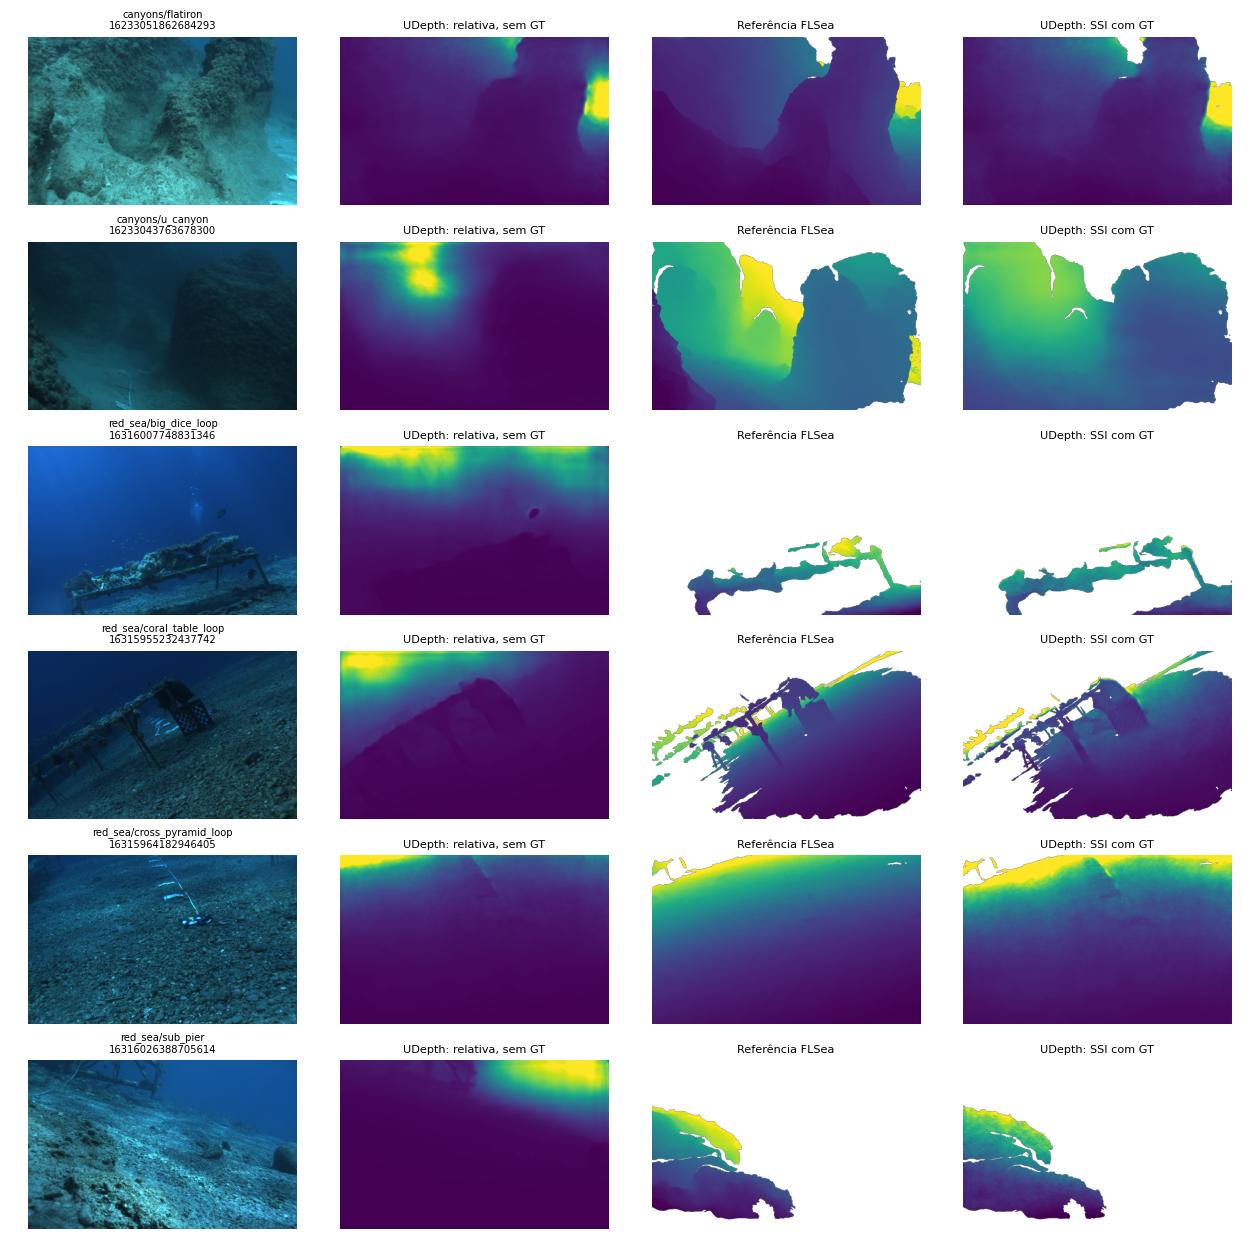

In [7]:
if EXIBIR_FIGURAS and SALVAR_PREDICOES:
    import matplotlib.pyplot as plt
    from PIL import Image
    from yolo_depth_underwater import flsea, metrics
    from IPython.display import Image as DisplayImage
    indice = pd.read_csv(ROOT/'predicoes_udepth/indice_relativas.csv',dtype={'frame_id':str})
    exemplos = indice.groupby('sequence',sort=False).first().reset_index()
    lookup = {(f.sequence,f.frame_id):f for f in FRAMES_ATUAIS}
    fig,axes = plt.subplots(len(exemplos),4,figsize=(14,2.3*len(exemplos)),squeeze=False)
    for i,row in enumerate(exemplos.itertuples()):
        bgr,gt = flsea.load_frame(lookup[(row.sequence,row.frame_id)])
        valid = metrics.valid_mask(gt)
        relative = np.load(ROOT/'predicoes_udepth'/row.relative_npy,allow_pickle=False)
        aligned = np.asarray(Image.open(ROOT/'predicoes_udepth/alinhadas_ssi'/(row.frame_id+'.png')),dtype=float)/1000
        lo,hi = np.percentile(gt[valid],[1,99])
        rlo,rhi = np.percentile(relative,[1,99])
        axes[i,0].imshow(bgr[...,::-1]);axes[i,0].set_title(row.sequence+'\n'+row.frame_id,fontsize=8)
        axes[i,1].imshow(relative,cmap='viridis',vmin=rlo,vmax=rhi);axes[i,1].set_title('UDepth: relativa, sem GT',fontsize=9)
        axes[i,2].imshow(np.ma.masked_where(~valid,gt),cmap='viridis',vmin=lo,vmax=hi);axes[i,2].set_title('Referência FLSea',fontsize=9)
        axes[i,3].imshow(np.ma.masked_where(~valid,aligned),cmap='viridis',vmin=lo,vmax=hi);axes[i,3].set_title('UDepth: SSI com GT',fontsize=9)
        for ax in axes[i]:ax.axis('off')
    fig.tight_layout()
    FIGURA_ATUAL = ROOT/'exemplos_atual.jpg'
    fig.savefig(FIGURA_ATUAL,dpi=90,pil_kwargs={'quality':75,'optimize':True})
    plt.close(fig)
    display(DisplayImage(filename=str(FIGURA_ATUAL)))


## Conclusão

A célula abaixo apresenta somente os números da execução validada com SILog λ = 1. SSI e mediana usam a referência no alinhamento; seus resultados medem estrutura relativa e não demonstram profundidade métrica independente. A comparação final com os colegas depende de CSVs produzidos com a mesma fórmula de SILog.

In [8]:
from IPython.display import Markdown, display
if 'RESULTADO_ATUAL' not in globals() or RESULTADO_ATUAL.get('status') != 'validacao_tecnica_concluida':
    raise RuntimeError('Execute e valide a seção 3 antes de apresentar a conclusão.')
linhas = ['O UDepth-RMI pré-treinado foi avaliado sem treinamento nos mesmos 119 frames válidos dos 120 pares fixados do FLSea-VI v5.',
          'A avaliação atual contém 357 registros: SSI, mediana e controle, com SILog λ = 1.']
for alinhamento,valores in RESULTADO_ATUAL['summary'].items():
    linhas.append(f"**{alinhamento}**: AbsRel={valores['AbsRel'][0]:.4f}; RMSE alinhado={valores['RMSE'][0]:.4f}; δ1={100*valores['d1'][0]:.2f}%; SILog={valores['SILog'][0]:.4f}.")
linhas.append('SSI e mediana usam o GT da própria imagem. Os mapas NPY originais permanecem relativos, sem referência na geração e sem calibração em metros.')
linhas.append(f"Foram verificados {RESULTADO_ATUAL['n_relative_maps']} NPYs e {RESULTADO_ATUAL['n_aligned_pngs']} PNGs SSI; os PNGs são auxiliares para visualização e usam a referência no alinhamento.")
linhas.append('Os CSVs antigos dos colegas não foram reexecutados aqui e seu SILog com λ = 0,85 não é comparável ao SILog atual.')
linhas.append('A execução usou '+str(RESULTADO_ATUAL['model_protocol']['device'])+', main '+RESULTADO_ATUAL['evaluator_commit']+' e a correção de exportação opcional da PR #2, com os hashes das fontes registrados.')
display(Markdown('\n\n'.join(linhas)))


O UDepth-RMI pré-treinado foi avaliado sem treinamento nos mesmos 119 frames válidos dos 120 pares fixados do FLSea-VI v5.

A avaliação atual contém 357 registros: SSI, mediana e controle, com SILog λ = 1.

**ssi**: AbsRel=0.1291; RMSE alinhado=0.9278; δ1=84.66%; SILog=17.5301.

**median**: AbsRel=0.2295; RMSE alinhado=1.6208; δ1=72.43%; SILog=25.3564.

**control**: AbsRel=0.3230; RMSE alinhado=1.6346; δ1=39.97%; SILog=44.3266.

SSI e mediana usam o GT da própria imagem. Os mapas NPY originais permanecem relativos, sem referência na geração e sem calibração em metros.

Foram verificados 119 NPYs e 119 PNGs SSI; os PNGs são auxiliares para visualização e usam a referência no alinhamento.

Os CSVs antigos dos colegas não foram reexecutados aqui e seu SILog com λ = 0,85 não é comparável ao SILog atual.

A execução usou cpu, main 1ad6133260c07cbcef754777b3f7390ade8e1a43 e a correção de exportação opcional da PR #2, com os hashes das fontes registrados.